# 🧠 바람이 바꾸는 산불 확산 — 딥러닝(신경망) 빈칸 실습

바람이 부는 날 숲에서 산불이 번지는 모습을 흉내 낸 연습용 데이터예요. 불은 옆 나무로 옮겨 붙고, 바람이 부는 쪽으로는 더 잘 번져요. 바람 방향과 세기를 바꾸면 어느 쪽 나무가 더 많이 타는지 알아보면 재미있어요.

**예측할 것:** 결과(숲 끝까지 번짐 여부) (0 또는 1) — 불이 숲 반대편 끝까지 번졌는지를 나눈 결과예요

> ⚠️ 연습용 합성 데이터(실제 측정 아님)

수업 「#20 당도 아삭함 과일 채소 딥러닝」·「MNIST 딥러닝」에서 배운 순서 그대로예요: 불러오기 → 거르기 → 정규화 → 신경망 설계(Sequential·Dense) → compile → fit → evaluate → predict.

`______` 빈칸에 알맞은 **함수 이름이나 낱말**을 넣고 ▶ 실행해요. 막히면 **오픈북** — 클래스룸 실습 파일을 펴 보고 같은 코드를 찾아 써요(단계마다 📖).

In [ ]:
# 0. 준비 — 그대로 실행해요
import pandas as pd

## 1. 데이터 불러오기
📖 **오픈북** — 「#20 과일 채소 딥러닝」 숙제00 `pd.read_csv(url)`

In [ ]:
dc = pd.______("https://baehwa-ai-2026.web.app/dataproject/csv/c106_c.csv")      # 힌트: CSV 를 읽는 함수
dc = dc.dropna(subset=["나무 밀도", "번질 확률", "남풍 세기", "서풍 세기", "결과(숲 끝까지 번짐 여부)"])      # 이번에 쓰는 열에 빈칸이 있는 줄만 지우기
print(dc.shape)
# 이상치 거르기 — 머신러닝 노트 3번과 같은 IQR
for col in ["나무 밀도", "번질 확률", "남풍 세기", "서풍 세기"]:
    q1, q3 = dc[col].quantile(0.25), dc[col].quantile(0.75)
    if q3 == q1 or dc[col].nunique() <= 5: continue      # 값 종류가 적은 열은 건너뛰기
    dc = dc[(dc[col] >= q1 - 1.5 * (q3 - q1)) & (dc[col] <= q3 + 1.5 * (q3 - q1))]
print('거른 뒤', dc.shape)

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

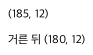

## 2. 특징(X)·정답(y) 고르고 0~1 로 맞추기(정규화)
신경망은 숫자 크기가 비슷해야 잘 배워요(예: 몸무게 50 과 키 160 을 둘 다 0~1 로). MNIST 에서 픽셀을 255 로 나눠 0~1 로 만든 것과 같은 일이에요. 먼저 학습용·시험용으로 나누고, **학습용의 최솟값·최댓값**으로 둘 다 맞춰요(시험지를 미리 보지 않기).

📖 **오픈북** — 「MNIST 딥러닝」 숙제03 정규화 · 「#20 과일 채소 딥러닝」 숙제01 `X = df[[...]]`, `y = df[...]`

In [ ]:
X = dc[["나무 밀도", "번질 확률", "남풍 세기", "서풍 세기"]]
y = dc["결과(숲 끝까지 번짐 여부)"]
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = ______(X, y, test_size=0.3, random_state=42)      # 힌트: 나누는 함수
mn, mx = X_train.min(), X_train.max()      # 정규화 기준은 학습용에서만 (시험지를 미리 보지 않기)
rng = (mx - mn).replace(0, 1)      # 값이 한 가지뿐인 열은 0 으로 나누지 않게
X_train, X_test = (X_train - mn) / rng, (X_test - mn) / rng      # 0~1 로 맞추기
print(len(X_train), len(X_test))

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)



## 3. 신경망 설계하기
입력층(4) → 은닉층(16) → 은닉층(8) → 출력층(2: 0 이냐 1 이냐).

- **층(Dense)** = 계산하는 칸(노드)이 한 줄로 모인 것. **은닉층**은 입력과 출력 사이에서 생각하는 칸들이에요.
- **16·8** = 칸 수. 정해진 답은 없어요 — 수업 과일 채소 실습(32·16)보다 데이터가 작아서 조금 줄였어요. 바꿔 보고 정확도가 어떻게 되는지 봐도 좋아요.
- **relu** = 음수는 0 으로 바꾸는 규칙(은닉층에 써요). **softmax** = 마지막 칸들을 「0일 확률·1일 확률」처럼 더해서 1 이 되게 바꾸는 규칙이에요.

📖 **오픈북** — 「#20 과일 채소 딥러닝」 숙제01 `Sequential()` · `Dense(32, input_dim=2, activation='relu')` · `Dense(3, activation='softmax')`

In [ ]:
from keras.models import Sequential
from keras.layers import Dense
model = ______()      # 힌트: 층을 차례로 쌓는 모델
model.add(______(16, input_dim=4, activation='relu'))      # 힌트: 층 이름
model.add(Dense(8, activation='relu'))
model.add(Dense(2, activation='______'))      # 힌트: 확률로 나오게 하는 활성화 함수

## 4. 학습 방법 정하기 (compile)
📖 **오픈북** — 「#20 과일 채소 딥러닝」 숙제02 · 「MNIST 딥러닝」 숙제07

In [ ]:
model.______(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])      # 힌트: 학습 방법 정하기(손실·최적화·평가 지표)

## 5. 학습하기 (fit) → 평가하기 (evaluate)
📖 **오픈북** — 「#20 과일 채소 딥러닝」 숙제03·04 · 「MNIST 딥러닝」 숙제07·08

In [ ]:
model.______(X_train, y_train, epochs=100, verbose=0)      # 힌트: 학습시키기 (verbose=0 은 진행 줄을 숨겨요)
print('시험 [손실, 정확도]', model.______(X_test, y_test, verbose=0))      # 힌트: 성능 평가
base = max(y_test.mean(), 1 - y_test.mean())
print('기준선 — 아무 계산 없이 더 많은 쪽으로만 찍어도', round(base, 2))

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

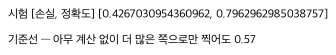

## 6. 예측해 보기 (predict)
📖 **오픈북** — 「MNIST 딥러닝」 숙제09 `model.predict` · `np.argmax`

In [ ]:
import numpy as np
p = model.______(X_test[:5], verbose=0)      # 힌트: 예측하기
print('예측', np.argmax(p, axis=1), '정답', list(y_test[:5]))

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)



## 7. 결과 읽기
보고서 「한계」 칸에 적어요.
- 정확도가 **기준선**(더 많은 쪽으로만 찍은 정확도)보다 높았나요? 기준선과 비슷하면 신경망이 거의 배운 게 없다는 뜻이에요.
- 머신러닝 노트의 점수(R²)와는 **재는 방법이 달라서** 숫자를 그대로 비교하면 안 돼요. R² 는 숫자를 얼마나 가깝게 맞혔는지, 정확도는 0·1 을 몇 개 맞혔는지예요.
- 데이터가 몇백 줄뿐이면 신경망이 꼭 좋지는 않아요 — 그것도 **발견**이에요.